In [1]:
import pandas as pd

import matplotlib.pyplot as plt
import numpy as np

from utils.pit.piece_wise_marginal import PiecewiseMarginal, to_normal, from_normal
from utils.pit.empirical_marginal import EmpiricalPiece
from utils.pit.gpd_marginal import GPDPiece

from utils.tv_var.harmonic_standardizer import HarmonicStandardizer

In [2]:
point = 'p102'
waves_df = pd.read_csv(f'inputs/waves_bulk_{point}.csv', index_col=0, parse_dates=True)

In [3]:
train = slice("1985-01-01", "2015-12-31")

marg = {
    "VHM0":  PiecewiseMarginal([EmpiricalPiece(), GPDPiece()], [0.95]).fit(waves_df.loc[train, "VHM0"]),
    "VTM02": PiecewiseMarginal([EmpiricalPiece()], []).fit(waves_df.loc[train, "VTM02"]),
}

#### 2. Toda la serie → probabilidad (cdf) → normal
z0 = pd.DataFrame({c: to_normal(pd.Series(marg[c].cdf(waves_df[c].values), index=waves_df.index))
                   for c in marg})

#### 3. Estandarización armónica (quita la estacionalidad), ajustada en entrenamiento
harm_z = HarmonicStandardizer(n_harmonics=3).fit(z0.loc[train])
z_bulk = harm_z.transform(z0)

findfont: Failed to find font weight semibold for Arial, now using 700.


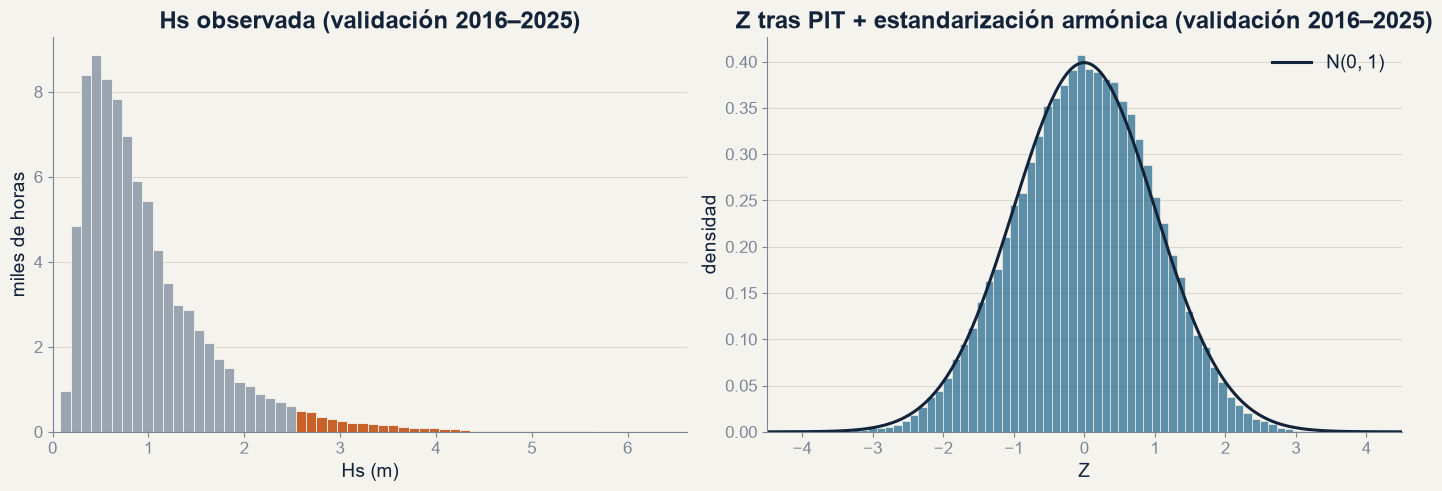

In [4]:
from scipy import stats



#### Estilo presentación
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 14, "axes.titlesize": 17, "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA,
    "xtick.color": GRIS, "ytick.color": GRIS,
})

hs = waves_df["VHM0"].dropna()
z = z_bulk["VHM0"].dropna()
u95 = hs.quantile(0.95)

per = slice("2016", "2025")
hs = waves_df.loc[per, "VHM0"].dropna()
z = z_bulk.loc[per, "VHM0"].dropna()

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True, facecolor=FONDO)

#### Panel 1: Hs observada (miles de horas)
cnt, bordes = np.histogram(hs, bins=60)
axs[0].bar(bordes[:-1], cnt / 1000, width=np.diff(bordes), align="edge",
           color=np.where(bordes[:-1] >= u95, NARANJA, "#9AA5B1"), edgecolor=FONDO, lw=0.6)

axs[0].set(title="Hs observada (validación 2016–2025)", xlabel="Hs (m)", ylabel="miles de horas", xlim=(0, hs.max() * 1.02))

#### Panel 2: Z tras PIT + armónicos
axs[1].hist(z, bins=60, density=True, color=AZUL, alpha=0.75, edgecolor=FONDO, lw=0.6)
x = np.linspace(-4.5, 4.5, 300)
axs[1].plot(x, stats.norm.pdf(x), color=TINTA, lw=2.2, label="N(0, 1)")
axs[1].set(title="Z tras PIT + estandarización armónica (validación 2016–2025)", xlabel="Z", ylabel="densidad", xlim=(-4.5, 4.5))
axs[1].legend(frameon=False, loc="upper right")

for ax in axs:
    ax.set_facecolor(FONDO)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#DDD8CE", lw=0.8)
    ax.set_axisbelow(True)
    ax.title.set_fontweight("semibold")

fig.savefig("figuras/pit_hs_z.png", dpi=200, facecolor=FONDO)
plt.show()

In [5]:
def z_a_fisico(z):
    z0_ = harm_z.inverse_transform(z)
    return pd.DataFrame({c: marg[c].ppf(from_normal(z0_[c]).values) for c in z.columns}, index=z.index)

#### 1. Ida y vuelta (física → Z → física)
back = z_a_fisico(z_bulk)
for c in marg:
    err = (back[c] - waves_df[c]).abs()
    print(f"{c}: error máx {err.max():.2e} | medio {err.mean():.2e} | peor {err.idxmax()}")

#### 2. Media y desviación de Z por mes, entrenamiento y test
for nombre, per in [("1985–2015", train), ("2016–2025", slice("2016", "2025"))]:
    zz = z_bulk.loc[per, "VHM0"]
    print(nombre); print(zz.groupby(zz.index.month).agg(["mean", "std"]).round(2).T.to_string(), "\n")

VHM0: error máx 9.15e-13 | medio 1.97e-16 | peor 2014-12-09 18:00:00
VTM02: error máx 8.26e-13 | medio 1.05e-16 | peor 2020-01-22 06:00:00
1985–2015
time    1    2     3     4     5     6     7     8     9     10    11    12
mean -0.01 -0.0 -0.04  0.05 -0.04 -0.00  0.04 -0.02  0.01 -0.04  0.05  0.01
std   0.98  1.0  1.00  1.00  1.02  0.98  1.01  1.00  1.01  0.99  0.99  1.02 

2016–2025
time    1     2     3     4     5     6     7     8     9     10    11    12
mean  0.12 -0.12  0.13  0.03 -0.01 -0.11  0.14 -0.02  0.04 -0.12  0.14 -0.16
std   0.98  0.94  0.91  0.96  0.96  0.97  0.86  1.09  0.99  0.95  0.95  0.96 



In [6]:
import os, pickle
os.makedirs("outputs/marginal", exist_ok=True)
pickle.dump({"marg": marg, "harm_z": harm_z}, open(f"outputs/marginal/transformacion_{point}.pkl", "wb"))
z_bulk.to_csv(f"outputs/marginal/z_bulk_{point}.csv")

findfont: Failed to find font weight semibold for Arial, now using 700.


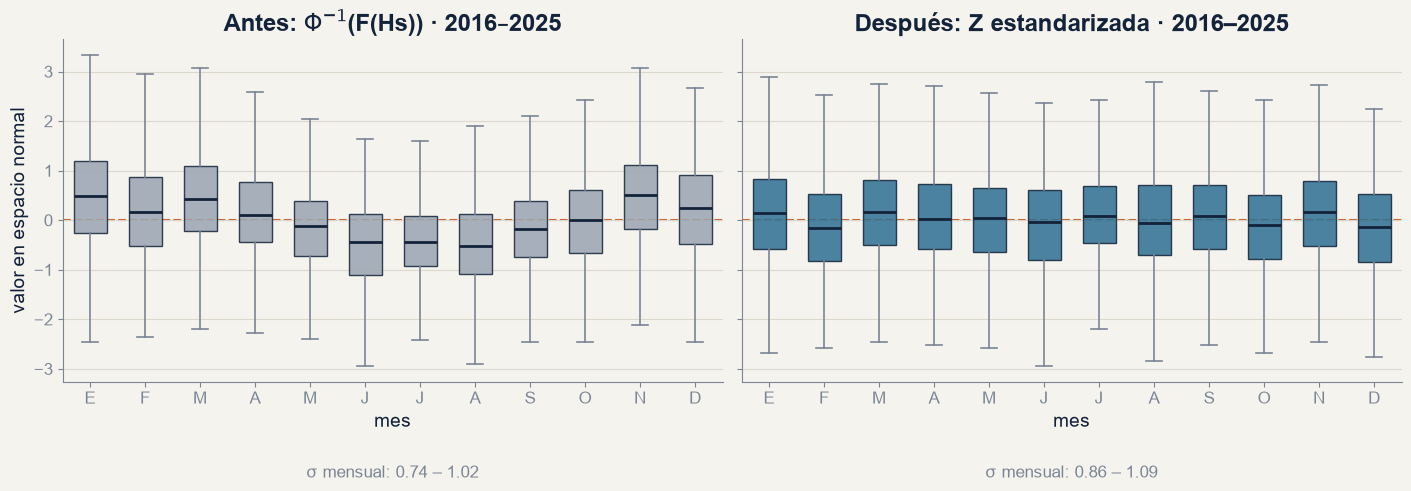

In [7]:
from scipy import stats

per = slice("2016", "2025")
hs = waves_df.loc[per, "VHM0"].dropna()
z = z_bulk.loc[per, "VHM0"].dropna()

#### Antes: x = Φ⁻¹(F(Hs)), aproximado con el rango empírico; después: Z
x = z0.loc[per, "VHM0"].dropna()

z_al = z.reindex(x.index).dropna()
meses = ["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True, facecolor=FONDO, sharey=True)

for ax, serie, color, titulo in [
    (axs[0], x, "#9AA5B1", r"Antes: $\Phi^{-1}$(F(Hs)) · 2016–2025"),
    (axs[1], z_al, AZUL, "Después: Z estandarizada · 2016–2025"),
]:
    datos = [serie[serie.index.month == m].values for m in range(1, 13)]
    bp = ax.boxplot(datos, widths=0.6, showfliers=False, patch_artist=True,
                    medianprops=dict(color=TINTA, lw=2),
                    whiskerprops=dict(color=GRIS, lw=1.2), capprops=dict(color=GRIS, lw=1.2),
                    boxprops=dict(edgecolor=TINTA, lw=1))
    for caja in bp["boxes"]:
        caja.set_facecolor(color)
        caja.set_alpha(0.85)
    ax.axhline(0, color=NARANJA, lw=1.5, ls="--", zorder=0)
    ax.set_xticks(range(1, 13), meses)
    ax.set(title=titulo, xlabel="mes")
    ax.set_facecolor(FONDO)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#DDD8CE", lw=0.8)
    ax.set_axisbelow(True)
    ax.title.set_fontweight("semibold")

axs[0].set_ylabel("valor en espacio normal")

#### σ mensual como texto bajo cada panel (lo que corrige la estandarización)
for ax, serie in [(axs[0], x), (axs[1], z_al)]:
    s = serie.groupby(serie.index.month).std()
    ax.text(0.5, -0.28, f"σ mensual: {s.min():.2f} – {s.max():.2f}", transform=ax.transAxes,
            ha="center", color=GRIS, fontsize=12)

fig.savefig("figuras/armonicos_boxplot_mes.png", dpi=200, facecolor=FONDO, bbox_inches="tight")
plt.show()